In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

In [2]:
df = pd.read_csv("D:/DATA/aitpune/college study thingy/ml/dataset/diabetes.csv")
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pregnancies    768 non-null    int64  
 1   Glucose        768 non-null    int64  
 2   BloodPressure  768 non-null    int64  
 3   SkinThickness  768 non-null    int64  
 4   Insulin        768 non-null    int64  
 5   BMI            768 non-null    float64
 6   Pedigree       768 non-null    float64
 7   Age            768 non-null    int64  
 8   Outcome        768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pedigree,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [4]:
df.isnull().sum()

Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Pedigree         0
Age              0
Outcome          0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df = df.dropna()
df = df.drop_duplicates()
print(df.shape)

(768, 9)


In [7]:
print(df["Outcome"].value_counts())

Outcome
0    500
1    268
Name: count, dtype: int64


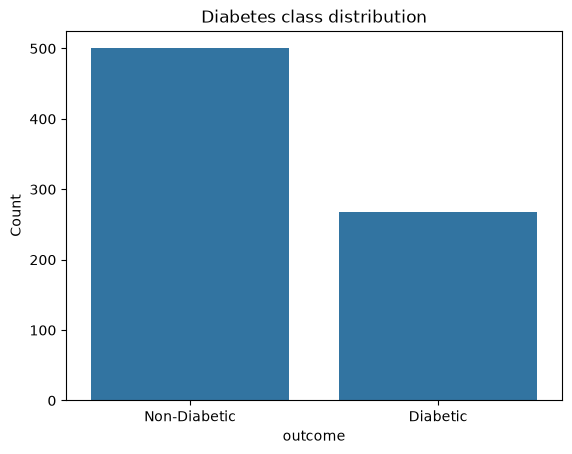

In [8]:
sns.countplot(x="Outcome", data =df)
plt.title("Diabetes class distribution")
plt.xlabel("outcome")
plt.ylabel("Count")
plt.xticks([0,1], ["Non-Diabetic", "Diabetic"])
plt.show()

In [9]:
X=df.drop(["Outcome"], axis=1)
y=df["Outcome"]
print("Features", X.shape)
print("Target", y.shape)

Features (768, 8)
Target (768,)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=22, stratify=y
)
print("Train feature", X_train.shape)
print("Test feature", X_test.shape)

Train feature (614, 8)
Test feature (154, 8)


In [11]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [12]:
# accuracy_values = []

# for k in range(1, 21):

#     knn = KNeighborsClassifier(n_neighbors=k)

#     knn.fit(X_train_scaled, y_train)

#     y_pred = knn.predict(X_test_scaled)

#     accuracy = accuracy_score(y_test, y_pred)

#     accuracy_values.append(accuracy)

#     print("K =", k, "Accuracy =", accuracy)

K = 1 Accuracy = 0.7792207792207793
K = 2 Accuracy = 0.7337662337662337
K = 3 Accuracy = 0.7792207792207793
K = 4 Accuracy = 0.7662337662337663
K = 5 Accuracy = 0.7922077922077922
K = 6 Accuracy = 0.7857142857142857
K = 7 Accuracy = 0.7987012987012987
K = 8 Accuracy = 0.8116883116883117
K = 9 Accuracy = 0.8181818181818182
K = 10 Accuracy = 0.8246753246753247
K = 11 Accuracy = 0.8246753246753247
K = 12 Accuracy = 0.8116883116883117
K = 13 Accuracy = 0.8116883116883117
K = 14 Accuracy = 0.8051948051948052
K = 15 Accuracy = 0.8181818181818182
K = 16 Accuracy = 0.8116883116883117
K = 17 Accuracy = 0.8116883116883117
K = 18 Accuracy = 0.7987012987012987
K = 19 Accuracy = 0.8051948051948052
K = 20 Accuracy = 0.7792207792207793


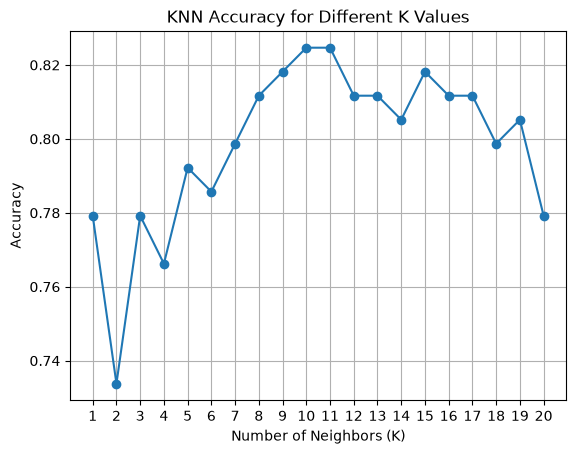

In [13]:
# plt.plot(range(1, 21), accuracy_values, marker='o')

# plt.xlabel('Number of Neighbors (K)')
# plt.ylabel('Accuracy')

# plt.title('KNN Accuracy for Different K Values')

# plt.xticks(range(1, 21))
# plt.grid()

# plt.show()

In [14]:
# best_k = accuracy_values.index(max(accuracy_values)) + 1

# print("Best K:", best_k)
# print("Best Accuracy:", max(accuracy_values) * 100, "%")

Best K: 10
Best Accuracy: 82.46753246753246 %


In [15]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)
print("KNN trained successfully")

KNN trained successfully


Confusion Matrix:
[[86 14]
 [24 30]]


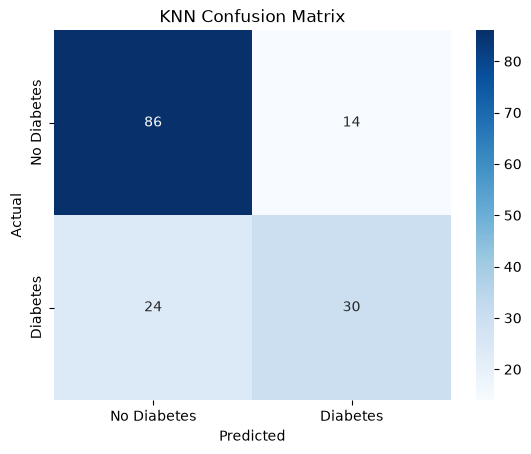

In [16]:
cm = confusion_matrix(y_test, knn_pred)

print("Confusion Matrix:")
print(cm)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Diabetes', 'Diabetes'],
    yticklabels=['No Diabetes', 'Diabetes']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('KNN Confusion Matrix')
plt.show()

In [17]:
result = pd.DataFrame({
    "Metric": ["accuracy", "precision", "recall", "f1 score", "error rate"],
    "Value":[
        accuracy_score(y_test, knn_pred),
        precision_score(y_test, knn_pred),
        recall_score(y_test, knn_pred),
        f1_score(y_test, knn_pred),
        1-accuracy_score(y_test, knn_pred)
    ]
})
print(result)

       Metric     Value
0    accuracy  0.753247
1   precision  0.681818
2      recall  0.555556
3    f1 score  0.612245
4  error rate  0.246753
